# Germany's Climate Responsibility: Carbon Debt, Budget Depletion, and Sectoral Trends

## Introduction

This notebook presents the calculation of Germany's historical climate responsibility and its remaining carbon budget. This analysis quantifies Germany's global position by integrating historical accountability into future emission pathways.

The core of this analysis is the **Carbon Budget**: the global limit of greenhouse gas (GHG) emissions allowed to achieve the Paris Agreement targets. To evaluate Germany's share and responsibility, three key metrics are defined:
* **Historical Carbon Debt:** The GHG emissions Germany has produced beyond its future population-based fair share.
* **Fair Share Emissions:** The future emissions allowed for Germany based on its share of the global population.
* **Adjusted Remaining Budget:** The remaining carbon budget for Germany, calculated by subtracting the historical carbon debt from the fair share emissions.

The main steps of this analysis include:

**1. Dataset Preparation:**
* **Destatis:** 2000–2023 Germany GHG emissions by economic activity.
* **EDGAR:** 1970-2023 Global historical GHG emissions.
* **UN DESA Population Division:** 1970-2100 Historical estimates and future projections of populations.

**2. Global Responsibility and Carbon Debt:**
* Calculation of the historical carbon debt and the adjusted remaining budget.
* Visualization of Germany's global ranking and climate responsibility.

**3. Budget Depletion Calculation:**
* **Business-as-Usual (BAU) Scenario:** Estimation of time remaining until budget depletion if Germany maintains 2023 emission levels.

**4. Future Pathway Evaluation:**
* **Net-Zero Pathway Scenario:** Evaluation of whether Germany's planned emission reductions can stay within its adjusted carbon budget.

**5. Sectoral Emission Trends:**
* A 20-year trend analysis of Germany's sectoral emissions.
* Identification of the top emitting sectors and evaluation of their reduction progress.

### Importing Core Libraries and the Modules
This analysis requires standard libraries for data manipulation (`pandas`, `numpy`) and interactive rendering (`plotly.express`, `IPython.display`). To maintain a clean notebook structure, the core analytical and visualization functions are imported from four custom Python modules:

* **`bin/carbonbudget.py`**: Calculates global carbon debt and budget allocations.
* **`bin/maps.py`**: Generates geographic visualizations.
* **`bin/futureanalysis.py`**: Evaluates Germany's future Business-As-Usual(BAU) and Net-zero emission pathway.
* **`bin/plotsectortable.py`**: Analyzes and formats sector-specific emission trends.

In [38]:
# Core Data & Visualization Libraries
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import display, HTML

# Custom Modules for Core Logic and Plotting
from carbonbudget import calculate_adjusted_carbon_budgets
from maps import plot_global_carbon_debt_map
from futureanalysis import analyze_german_bau_pathway, analyze_german_netzero_pathway
from plotsectortable import generate_sectoral_emissions_table

## 1. Data Loading and Preprocessing

### Germany Greenhouse Gas Emissions Data

The main dataset provides Germany's GHG emissions from 2000 to 2023. The raw data includes variables such as emission sources (e.g., Energy use, Road transport), GHG types, industry sectors, and aggregated totals based on different accounting standards.

This analysis extracts two core metrics: **(1) national total emissions by year** and **(2) sectoral emissions by year**. The following filtering criteria are applied:

* **Accounting Standard:** Data is filtered using the Kyoto Protocol Total, the standard framework for reporting national GHG inventories.
* **Sectoral Scope:** The sectoral breakdown includes All economic activities and Private households.
* **Greenhouse Gas Type:** Total CO₂ equivalent is used to aggregate all greenhouse gases into a single metric.

> **Note:** The raw dataset uses a semicolon (`;`) delimiter. The `sep=';'` parameter is required when loading the data via `pandas.read_csv()`.

Below is an overview of the raw emission data structure:


| Column Name | Description | Data Examples |
| :--- | :--- | :--- |
| **time** | Measurement Year | 2000, 2005, 2023... |
| **2_variable_attribute_label** | Emission Source Category | Energy use, Road transport, Other processes |
| **3_variable_attribute_label** | Greenhouse Gas Type | Carbon dioxide ($CO_2$), Methane ($CH_4$), Total, etc. |
| **4_variable_attribute_label** | Industry Sector (WZ 2008) | Manufacture of paper, Fishing, etc.  |
| **value_variable_label** | Emission Accounting Standard | Kyoto Protocol Total, All economic activities, Private households, etc. |
| **value** | Actual Emission Value | 4262142.558 (Numeric) |
| **value_unit** | Unit of Measurement | $t\ CO_2eq$ (tonnes of $CO_2$ equivalent) |

In [39]:
raw_df = pd.read_csv(
        "../data:/85111-0005_en_flat.csv",
        sep=';',                    # Destatis commonly uses semicolons
        encoding='utf-8')           # Use 'cp1252' if utf-8 throws an error

### Extracting National Total Emissions

This step prepares the raw greenhouse gas data to create an aggregated time-series of Germany's national total emissions for the carbon budget analysis.

The main steps include:
* **Data Filtering:** Rows are isolated where the accounting standard is the "Kyoto Protocol Total" and the greenhouse gas type is "Total".
* **Data Type Conversion:** Emission values are converted to numeric types (`pd.to_numeric`) for mathematical calculations.
* **Aggregation:** Data is grouped by year (`time`) and emission values are summed. This combines the three emission sources (Energy use, Road transport, and Other processes) into one annual total.
* **Standardization:** Columns are renamed (`year` and `emission`), and the index is reset for further analysis.

In [40]:
# Filter data - only extract total emissions of year
total_em = raw_df[
    (raw_df['value_variable_label'] == 'Total greenhouse gas emissions acc. Kyoto Protocol') &
    (raw_df['3_variable_attribute_label'] == 'Total') # Using Total CO2e
].copy()

# Data type checking - change object data to numeric data for calculating
total_em['value'] = pd.to_numeric(total_em['value'], errors='coerce')

# Data accumulation - calculating sum emissions of all 3 sub-groups (Energy use, Road transport, Other processes)
total_em = total_em.groupby('time')['value'].sum().reset_index()

# Change the data column name
total_em = total_em[['time', 'value']].rename(columns={
    'time': 'year',
    'value': 'emission'
}).reset_index(drop=True)

In [41]:
# Checking the dataframe structure
total_em.head()

,year,emission
0,2000,1.069205e+09
1,2001,1.087054e+09
2,2002,1.066397e+09
3,2003,1.070541e+09
4,2004,1.058412e+09


### Structuring Sectoral and Sub-Sectoral Emissions

This step prepares the sectoral emission datasets. The raw Destatis data mixes top-level parent sectors (18 economic activities, e.g., `WZ08-A`) and nested sub-sectors (numeric codes., e.g., `WZ08-01`) in the same column. Separating this hierarchy prevents double-counting.

Additionally, the manufacturing sector contains a nested hierarchy of sub-sectors, which requires manual filtering.

The main steps include:
* **Extracting Top-Level Sectors:** Regular expressions (`^WZ08-[A-Z]+`) isolate the 18 top-level economic sectors. This filters out lower-level sub-sectors to avoid data duplication.
* **Integrating Private Households:** Household emissions are extracted and appended to the main dataframe. This completes the national scope: *All Economic Activities (18 Sectors) + Private Households = Total National Emissions (19 Sectors)*.
* **Isolating Manufacturing Sub-Sectors:** A specific list of 19 sub-sector codes (e.g., `WZ08-10-03` to `WZ08-33`) is manually filtered to analyze the manufacturing industry.
* **Data Integrity Validation:** Automated checks using `np.isclose` ensure calculation accuracy. 
    1. The sum of the 18 economic sectors must match the official aggregated total.
    2. The sum of the selected manufacturing sub-sectors must match the official parent sector (`WZ08-C`) total.

#### Top-level economic sectors

In [42]:
# Filter data - only extract sectoral emissions
sector_em_raw = raw_df[
    (raw_df['value_variable_label'] == 'Greenhouse gas emissions') &
    (raw_df['3_variable_attribute_label'] == 'Total') &
    (raw_df['4_variable_attribute_code'].str.match(r'^WZ08-[A-Z]+(-[A-Z]+)*$', na=False))
    # Not include all 67 sectors, only include higher economic sector classification (e.g., WZ08-A)
].copy()

# Convert value to numeric (crucial for correct summation)
sector_em_raw['value'] = pd.to_numeric(sector_em_raw['value'], errors='coerce')

# Rename the column of data
rename_dict = {
    "time": "year",
    "4_variable_attribute_label": "sector_name",
    "4_variable_attribute_code": "sector_code",
    "2_variable_attribute_label": "source",
    "value": "emission"
}
sector_em = sector_em_raw[list(rename_dict.keys())].rename(columns=rename_dict)

# Calculate the sum for whole sectors
calculated_total = sector_em.groupby('year')['emission'].sum()

# Test the data with offical sum data for validating
official_sector_total = raw_df[
    (raw_df['value_variable_label'] == 'Greenhouse gas emiss. of all economic activities') &
    (raw_df['3_variable_attribute_label'] == 'Total')
].copy()
official_sector_total['value'] = pd.to_numeric(official_sector_total['value'], errors='coerce')
official_sector_total_series = official_sector_total.groupby('time')['value'].sum()

comparison = np.isclose(calculated_total, official_sector_total_series)
if comparison.all():
    print("Match")
else:
    mismatched_years = calculated_total.index[~comparison]
    print(f"Mismatch found in years: {list(mismatched_years)}")

Match


In [43]:
household_raw = raw_df[
    (raw_df['value_variable_label'] == 'Greenhouse gas emissions of private households') &
    (raw_df['3_variable_attribute_label'] == 'Total')
].copy()
household_df = household_raw.rename(columns={
    "time": "year",
    "2_variable_attribute_label": "source",
    "value": "emission"
})
household_df["sector_name"] = "Private Households"
household_df["sector_code"] = "HH"  # Dummy code for households
target_columns = ["year", "sector_name", "sector_code", "source", "emission"]
household_df = household_df[target_columns].copy()

# Convert emission to numeric type
household_df["emission"] = pd.to_numeric(household_df["emission"], errors="coerce")
sector_em = pd.concat([sector_em, household_df], ignore_index=True)

In [44]:
# Checking the dataframe structure
sector_em.head()

,year,sector_name,sector_code,source,emission
0,2008,Mining and quarrying,WZ08-B,Other processes,5.226395e+06
1,2010,"Electricity, gas, steam, air conditioning supply",WZ08-D,Road transport,6.625116e+05
2,2002,Human health and social work activities,WZ08-Q,Energy use,6.876039e+06
3,2017,"Water supply,sewerage,waste management,remedia...",WZ08-E,Other processes,1.176431e+07
4,2010,Mining and quarrying,WZ08-B,Other processes,3.879621e+06


#### Manufacturing sub-sectors

In [45]:
# Filter data - only extract manufacturing sub-sector emissions (WZ08-10 to WZ08-33)
mfg_sub_list = ['WZ08-10-03', 'WZ08-13-04', 'WZ08-16', 'WZ08-17', 'WZ08-18', 'WZ08-19', 'WZ08-20', 'WZ08-21','WZ08-22', 'WZ08-23', 'WZ08-24', 'WZ08-25', 'WZ08-26', 'WZ08-27', 'WZ08-28', 'WZ08-29', 'WZ08-30', 'WZ08-31-02', 'WZ08-33']
mfg_sub_raw = raw_df[
    (raw_df['value_variable_label'] == 'Greenhouse gas emissions') &
    (raw_df['3_variable_attribute_label'] == 'Total') &
    (raw_df['4_variable_attribute_code'].isin(mfg_sub_list))
].copy()

# Convert value to numeric (crucial for correct summation)
mfg_sub_raw['value'] = pd.to_numeric(mfg_sub_raw['value'], errors='coerce')

# Rename the column of data
rename_dict = {
    "time": "year",
    "4_variable_attribute_label": "sector_name",
    "4_variable_attribute_code": "sector_code",
    "2_variable_attribute_label": "source",
    "value": "emission"
}
mfg_sub_em = mfg_sub_raw[list(rename_dict.keys())].rename(columns=rename_dict)

# Calculate the sum for manufacturing sub-sectors by mfg_sub_em data
calculated_mfg_total = mfg_sub_em.groupby('year')['emission'].sum()

# Extract official WZ08-C (Manufacturing parent) total for validating
# Comparing against the parent sector 'WZ08-C' to ensure sub-sectors sum up correctly
official_mfg_parent = raw_df[
    (raw_df['value_variable_label'] == 'Greenhouse gas emissions') &
    (raw_df['3_variable_attribute_label'] == 'Total') &
    (raw_df['4_variable_attribute_code'] == 'WZ08-C')
].copy()

official_mfg_parent['value'] = pd.to_numeric(official_mfg_parent['value'], errors='coerce')
official_mfg_parent_series = official_mfg_parent.groupby('time')['value'].sum()

# Test the data with official parent sector data for validating
comparison = np.isclose(calculated_mfg_total, official_mfg_parent_series)
if comparison.all():
    print("Match")
else:
    mismatched_years = calculated_mfg_total.index[~comparison]
    print(f"Mismatch found in years: {list(mismatched_years)}")

Match


In [46]:
mfg_sub_em.head()

,year,sector_name,sector_code,source,emission
2881,2021,Manufacture of other transport equipment,WZ08-30,Energy use,3.995959e+05
2884,2006,Manufacture of coke and refined petroleum prod...,WZ08-19,Energy use,2.948588e+07
2907,2015,Manufacture of coke and refined petroleum prod...,WZ08-19,Road transport,6.238636e+04
2993,2017,"Manuf. of motor vehicles, trailers, semi-trailers",WZ08-29,Road transport,8.055341e+05
2994,2020,Manufacture of machinery and equipment n.e.c.,WZ08-28,Road transport,5.395990e+05


### Global Historical Emissions

The EDGAR database provides historical greenhouse gas emissions data to calculate global and national carbon budgets. The raw data is provided in a wide format and measured in Mega tonnes (Mt). To ensure consistency with the Destatis dataset, the data is reshaped into a long format, and emission values are converted to standard tonnes.

A methodological difference exists: Germany's annual emission totals in the EDGAR dataset differ slightly from the official Destatis records. Therefore, the EDGAR dataset is used exclusively for global-level calculations (e.g., global carbon budgets, cross-country comparisons), while the Destatis dataset is used for detailed, single-country analysis of Germany.

In [47]:
global_emission_raw_df = pd.read_csv('../data:/EDGAR_2025_GHG.csv')

# Reshape the data (Wide to Long)
em_id_cols = ['EDGAR Country Code', 'Country']
em_year_cols = [col for col in global_emission_raw_df.columns if col not in em_id_cols]

global_em = global_emission_raw_df.melt(
    id_vars=em_id_cols,
    var_name='year',
    value_name='emission_Mt'
)

# Renaming
global_em = global_em.rename(columns={
    'EDGAR Country Code': 'country_code',
    'Country': 'country_name_em'
})

# Numeric conversion
global_em['year'] = pd.to_numeric(global_em['year'])
global_em['emission'] = pd.to_numeric(global_em['emission_Mt'], errors='coerce')
global_em['emission'] = global_em['emission_Mt'] * 10**6  # Mega ton to ton
global_em = global_em.drop(columns=['emission_Mt'])

In [48]:
# Checking the dataframe structure
global_em.head()

,country_code,country_name_em,year,emission
0,ABW,Aruba,1970,3.696956e+04
1,AFG,Afghanistan,1970,1.529996e+07
2,AGO,Angola,1970,1.883435e+07
3,AIA,Anguilla,1970,3.397521e+03
4,AIR,International Aviation,1970,1.724780e+08


### Global Population Estimates and Projections

Assessing a nation's fair share of the carbon budget requires both past and future demographic data. Historical population data is used to calculate carbon debt, which measures how much past emissions exceeded the population-based fair share. Future population projections up to 2050 are used to allocate the remaining carbon budget.

This analysis uses UN DESA demographic indicators. The data includes historical estimates from 1960 to 2023 and 'Medium Fertility' projections from 2024 to 2100. During preprocessing, the raw dataset is loaded, column names are standardized for consistency, and the year and population columns are converted to numeric data types.

In [49]:
population_raw_df = pd.read_csv('../data:/WPP2024_GEN_F01_DEMOGRAPHIC_INDICATORS_COMPACT.csv')

# Renaming for consistency
global_pop = population_raw_df.rename(columns={
    'Country Code': 'country_code',
    'Country Name': 'country_name_pop',
    'Year': 'year',
    'Population': 'population'
})

# Select only the necessary columns for the carbon budget allocation
global_pop = global_pop[['country_name_pop', 'country_code', 'year', 'population']]

# Convert 'year' and 'population' to numeric types to prevent downstream calculation errors
global_pop['year'] = pd.to_numeric(global_pop['year'])
global_pop['population'] = pd.to_numeric(global_pop['population'])

# Checking the dataframe structure
global_pop.head()

,country_name_pop,country_code,year,population
0,Burundi,BDI,1950,2229322
1,Burundi,BDI,1951,2280554
2,Burundi,BDI,1952,2330938
3,Burundi,BDI,1953,2380670
4,Burundi,BDI,1954,2429703


### Joining Emissions and Population Datasets

Although both global emission and population datasets use standard country codes, differences in statistical scopes cause a mismatch in covered territories. To ensure accuracy, the analysis is restricted to countries present in both datasets. 

This is achieved by computing the intersection of valid country codes and filtering the data. An outer join is then performed based on country code and year. Finally, the timeline is standardized, incomplete records are removed, and a sanity check is conducted. Set operations are used to isolate, quantify, and print the countries excluded from either dataset.

In [50]:
# Identify countries present in both datasets to maintain the "inner join" logic for countries
valid_countries = set(global_em['country_code']).intersection(set(global_pop['country_code']))

# Filter both datasets to keep only valid countries
em_filtered = global_em[global_em['country_code'].isin(valid_countries)]
pop_filtered = global_pop[global_pop['country_code'].isin(valid_countries)]

# Outer Join to keep future years from population data (where emissions data is NaN)
global_em_pop = pd.merge(
    em_filtered,
    pop_filtered[['country_code', 'year', 'population']],
    on=['country_code', 'year'],
    how='outer'
)

# Clean up: Remove rows where population is missing
global_em_pop = global_em_pop.dropna(subset=['population'])

# Filter for the extended analysis period (1960 to 2100 to include future projections)
global_em_pop = global_em_pop[global_em_pop['year'].between(1970, 2050)]

In [51]:
# Extract unique country codes as sets
em_codes = set(global_em['country_code'].dropna().unique())
pop_codes = set(global_pop['country_code'].dropna().unique())

# Calculate intersection and differences using set operations
overlapping_codes = em_codes.intersection(pop_codes)
only_in_em = em_codes - pop_codes
only_in_pop = pop_codes - em_codes

# Print the number of overlapping and non-overlapping countries
print(f"Number of overlapping countries: {len(overlapping_codes)}")
print(f"Number of countries ONLY in Emission data: {len(only_in_em)}")
print(f"Number of countries ONLY in Population data: {len(only_in_pop)}\n")

# Display the specific countries missing from either dataset
# Use drop_duplicates() to show each country only once
if len(only_in_em) > 0:
    print("--- Countries in Emission data BUT NOT in Population data ---")
    missing_in_pop = global_em[global_em['country_code'].isin(only_in_em)][['country_code', 'country_name_em']].drop_duplicates()
    print(missing_in_pop.to_string(index=False))
    print("\n")

if len(only_in_pop) > 0:
    print("--- Countries in Population data BUT NOT in Emission data ---")
    missing_in_em = global_pop[global_pop['country_code'].isin(only_in_pop)][['country_code', 'country_name_pop']].drop_duplicates()
    print(missing_in_em.to_string(index=False))

Number of overlapping countries: 206
Number of countries ONLY in Emission data: 6
Number of countries ONLY in Population data: 31

--- Countries in Emission data BUT NOT in Population data ---
country_code        country_name_em
         AIR International Aviation
         ANT                Curaçao
         SCG  Serbia and Montenegro
         SEA International Shipping
        EU27                   EU27
GLOBAL TOTAL           GLOBAL TOTAL


--- Countries in Population data BUT NOT in Emission data ---
country_code                 country_name_pop
         MYT                          Mayotte
         SSD                      South Sudan
         PSE               State of Palestine
         GGY                         Guernsey
         IMN                      Isle of Man
         JEY                           Jersey
         AND                          Andorra
         VAT                         Holy See
         XKX    Kosovo (under UNSC res. 1244)
         MNE                   

In [52]:
# Checking the dataframe structure
global_em_pop.head()

,country_code,country_name_em,year,emission,population
20,ABW,Aruba,1970,36969.560,59020
21,ABW,Aruba,1971,41825.240,58881
22,ABW,Aruba,1972,52708.352,58680
23,ABW,Aruba,1973,57704.309,59111
24,ABW,Aruba,1974,56999.430,59760


With all data preprocessing steps completed, the datasets are structured and ready for the core analytical phases. The Germany-specific greenhouse gas analysis utilizes the `total_em` and `sector_em` (including `mfg_sub_em`) dataframes. The global carbon budget and fair share calculations rely on the harmonized `global_em_pop` dataframe.

## 2. Global Carbon Budget Calculation

### Total Global Carbon Budget

To address the first research question regarding Germany's responsibility for the global carbon budget, the remaining global carbon budget is calculated based on the Paris Agreement targets (1.5°C and 2.0°C).

Official estimates from the IPCC report are used. The IPCC calculates the remaining carbon budget from the beginning of 2020. For a 67% likelihood of limiting global warming, the estimated budgets are 400 GtCO₂ for 1.5°C and 1150 GtCO₂ for 2.0°C.

To update the remaining carbon budget to start from the beginning of 2024, total global emissions from 2020 to 2023 must be subtracted. The `global_em_pop` dataframe is used for this calculation.

In [53]:
# Filter global emissions data for the period 2020-2023
emissions_2020_to_2023 = global_em_pop[global_em_pop['year'].between(2020, 2023)]

# Calculate the total global emissions
total_emissions_tonnes = emissions_2020_to_2023['emission'].sum()

# Convert tonnes to Gigatonnes (Gt)
total_emissions_gt = total_emissions_tonnes / 1e9

print(f"Total global emissions from 2020 to 2023: {total_emissions_gt:.2f} GtCO2")

# Calculate the Remaining Global Carbon Budget for 2024
# IPCC budgets as of early 2020
budget_2020_1_5C = 400.0  # GtCO2 for 1.5 degrees
budget_2020_2_0C = 1150.0 # GtCO2 for 2.0 degrees

# Deduct the emissions of 2020-2023 from the initial budgets
budget_2024_1_5C = budget_2020_1_5C - total_emissions_gt
budget_2024_2_0C = budget_2020_2_0C - total_emissions_gt

# Display the final updated budgets for 2024
print("--- Remaining Global Carbon Budget (As of 2024) ---")
print(f"For 1.5 degrees target: {budget_2024_1_5C:.2f} GtCO2")
print(f"For 2.0 degrees target: {budget_2024_2_0C:.2f} GtCO2")

Total global emissions from 2020 to 2023: 199.64 GtCO2
--- Remaining Global Carbon Budget (As of 2024) ---
For 1.5 degrees target: 200.36 GtCO2
For 2.0 degrees target: 950.36 GtCO2


### Carbon Budget Allocation

Allocating the global carbon budget among nations is a highly debated topic. Methods based on current emission ratios are often criticized for ignoring historical cumulative emissions. To address this inequality, a population-based allocation method is applied in this analysis. 

The calculation relies on three core concepts: historical carbon debt, fair share allocation, and the adjusted remaining budget. The specific mathematical steps, implemented in the `calculate_adjusted_carbon_budgets` function, are defined as follows:

> **1. Historical Carbon Debt (1970–2023)**

Debt is calculated by subtracting the population-based allocated emissions from the actual total national emissions between 1970 and 2023. A positive value indicates over-emission (debt), while a negative value indicates a surplus.
$$Debt_{i} = \sum_{t=1970}^{2023} E_{i}(t) - \left( \sum_{t=1970}^{2023} E_{global}(t) \times \frac{\sum_{t=1970}^{2023} P_{i}(t)}{\sum_{t=1970}^{2023} P_{global}(t)} \right)$$

>**2. Fair Share Allocation (2024–2050)**

The remaining global carbon budget from 2024 is distributed according to each country's projected cumulative population share from 2024 to 2050.
$$FairShare_{i} = Budget_{global,2024} \times \frac{\sum_{t=2024}^{2050} P_{i}(t)}{\sum_{t=2024}^{2050} P_{global}(t)}$$

>**3. Adjusted Remaining Budget**

The final true budget is calculated by subtracting the historical carbon debt from the fair share allocation.
$$AdjustedBudget_{i} = FairShare_{i} - Debt_{i}$$


The function is applied to all countries in the `global_em_pop` dataframe for the 1.5°C and 2.0°C climate targets. The calculated values are stored in the debt, fair share, and adjusted budget columns.

In [54]:
# Call the function and store the result in a variable
result_1_5C = calculate_adjusted_carbon_budgets(global_em_pop, target_budget = budget_2024_1_5C, hist_start=1970, hist_end=2023, future_start=2024, future_end=2050)

# Display the first 10 rows (Countries with largest carbon debt)
result_1_5C.head(10)

,country_name_em,country_code,debt,fair_share,adjusted_budget
194,United States,USA,253.040391,8.193128,-244.847263
158,Russia,RUS,77.423651,3.143613,-74.280038
48,Germany,DEU,33.222000,1.829462,-31.392537
31,Canada,CAN,25.807279,0.966859,-24.840420
97,Japan,JPN,26.553870,2.580408,-23.973463
9,Australia,AUS,20.320667,0.665003,-19.655665
67,United Kingdom,GBR,18.015179,1.635289,-16.379890
160,Saudi Arabia,SAU,16.002026,0.915787,-15.086239
192,Ukraine,UKR,15.659084,0.812755,-14.846329
149,Poland,POL,14.204021,0.805700,-13.398321


In [55]:
# Call the function and store the result in a variable
result_2_0C = calculate_adjusted_carbon_budgets(global_em_pop, target_budget = budget_2024_2_0C, hist_start=1970, hist_end=2023, future_start=2024, future_end=2050)

# Display the first 10 rows (Countries with largest deficit) as a styled table in Jupyter
result_2_0C.head(10)

,country_name_em,country_code,debt,fair_share,adjusted_budget
194,United States,USA,253.040391,38.862679,-214.177711
158,Russia,RUS,77.423651,14.911182,-62.512469
48,Germany,DEU,33.222000,8.677737,-24.544262
31,Canada,CAN,25.807279,4.586127,-21.221152
9,Australia,AUS,20.320667,3.154325,-17.166343
97,Japan,JPN,26.553870,12.239715,-14.314155
192,Ukraine,UKR,15.659084,3.855163,-11.803921
160,Saudi Arabia,SAU,16.002026,4.343876,-11.658150
149,Poland,POL,14.204021,3.821699,-10.382323
67,United Kingdom,GBR,18.015179,7.756711,-10.258469


The selection of a baseline year for calculating historical responsibility is an important methodological choice. Two primary approaches are debated:

- **1990 Baseline:** This year aligns with the IPCC First Assessment Report. It marks the formal scientific consensus connecting human activities to global warming.

- **1970 Baseline (Applied in this analysis):** This year corresponds to the earliest available global data. It enforces a stricter standard of accountability.

A 1970 baseline ensures a more comprehensive assessment. It accounts for early industrial expansion and economic wealth accumulation. This approach recognizes the climate impact of emissions generated before global warming was formally recognized by the international community.

### Geographic Visualization of Carbon Debt

The calculated global carbon budget results are visualized on an interactive global map. Specific data for each country is displayed upon hovering the cursor over the map. To ensure full interactivity, the Jupyter Notebook must be opened in a standard interactive environment rather than a static preview mode.

In [56]:
# Plot global carbon debt map
fig_map = plot_global_carbon_debt_map(global_carbon_budget=result_1_5C,
                            country_code_column='country_code',
                            carbon_debt_column='debt',
                            country_name_column='country_name_em',
                            title="Global Carbon Debt: Geographic Distribution (1.5°C Target)")

fig_map.show()

Sanity Check Passed: 206 out of 206 records are ready for mapping.



Germany holds the third-largest carbon debt globally. Under the 1.5°C target framework, this cumulative debt exceeds 33 GtCO₂eq. 

## 3. Germany Future Emission Scenarios

With Germany's global carbon budget allowance established, the analysis transitions to projecting future emission scenarios. Two distinct pathways are explored to address the following research questions:

**How many years are left before Germany's carbon budget is exhausted under a business-as-usual (BAU) scenario?**
The BAU scenario assumes that Germany maintains its emissions at the current level. The time remaining until complete budget depletion is calculated and visualized using the `analyze_german_bau_pathway` function.

**Is the committed German net-zero policy sufficient to limit global warming within the carbon budget perspective?**
The net-zero scenario evaluates whether Germany's official climate targets align with its adjusted global carbon budget. This policy pathway is assessed using the `analyze_german_netzero_pathway` function.

### If Germany maintain its emissions, how many years left?
The Business-As-Usual (BAU) projection assesses the climate impact if no further emission reductions are achieved. The exact budget depletion date is calculated by dividing the total allocated fair share budget by the constant 2023 annual emission rate. An average fair annual budget is derived by distributing the total remaining carbon budget evenly across the timeline up to 2050.

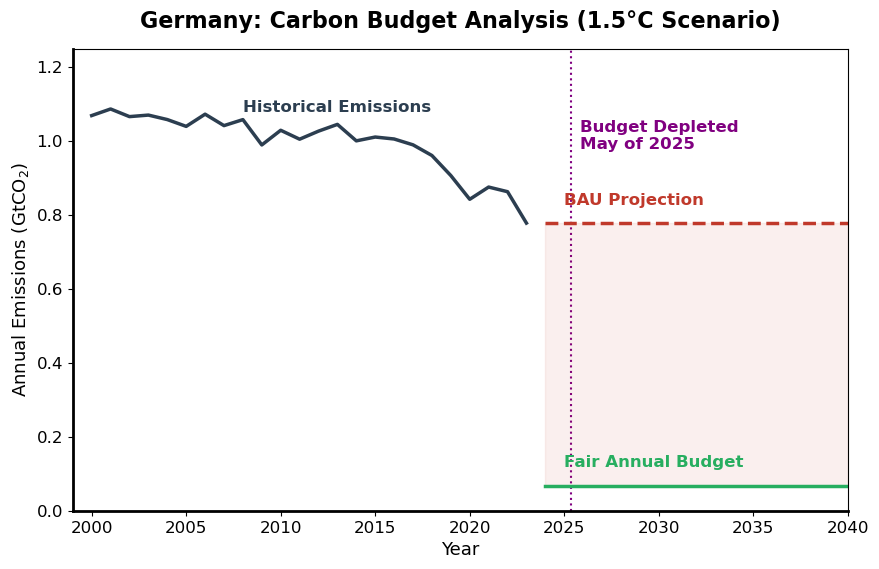


  ANALYSIS SUMMARY FOR GERMANY (DEU) | 1.5°C SCENARIO
  ● Allocated Fair Share (2024-2050)      : 1.83 GtCO2
  ● Current Annual Emission (2023)        : 0.78 GtCO2
  ● Time left under BAU                   : 2 years 4 months
  ● Actual Time (Depletion Date)          : May of 2025
  ● Individual fair allowance             : 21.60 tCO2 per person (Total until 2050)



In [57]:
analyze_german_bau_pathway(result_1_5C, global_em_pop, total_em, "1.5")

Looking at the numerical output from our BAU analysis, the reality of Germany’s remaining carbon budget under the 1.5°C target becomes very clear. To keep global warming within the 1.5°C limit, Germany’s allocated fair share of emissions from 2024 all the way to 2050 is strictly capped at 1.83 GtCO₂. 

Now, if emissions are kept constant at the 2023 level per year, this remaining budget is calculated to last for exactly 2 years and 4 months. This places the definitive depletion date in May 2025. This means that, from a carbon budget perspective, Germany has theoretically exhausted its entire multi-decade allowance. 

To put this into a more personal perspective, dividing this entire remaining budget by the national population leaves an individual allowance of just 21.60 tCO₂ per person for the entire period up to 2050. These metrics demonstrate that the current emission trajectory is unsustainable for limiting global warming.

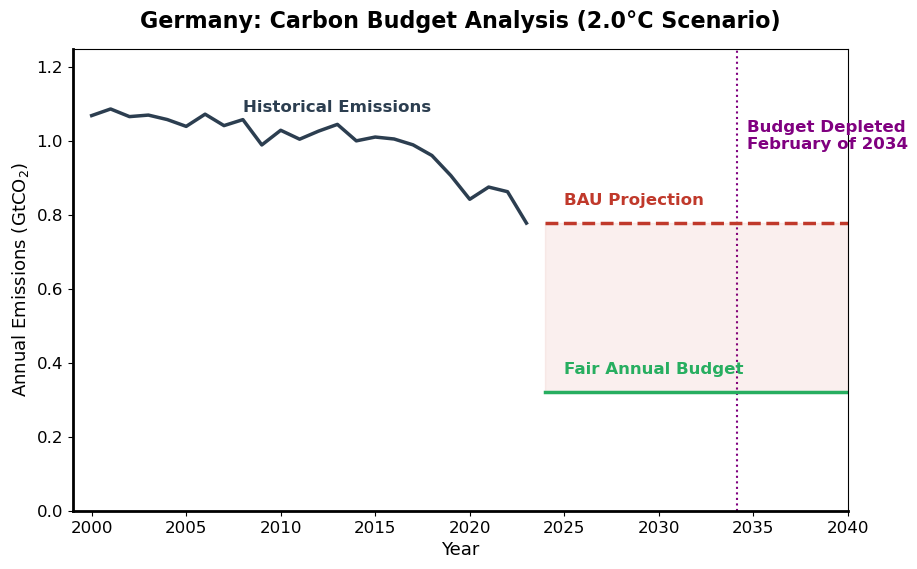


  ANALYSIS SUMMARY FOR GERMANY (DEU) | 2.0°C SCENARIO
  ● Allocated Fair Share (2024-2050)      : 8.68 GtCO2
  ● Current Annual Emission (2023)        : 0.78 GtCO2
  ● Time left under BAU                   : 11 years 2 months
  ● Actual Time (Depletion Date)          : February of 2034
  ● Individual fair allowance             : 102.46 tCO2 per person (Total until 2050)



In [58]:
analyze_german_bau_pathway(result_2_0C, global_em_pop, total_em, "2.0")

Switching over to the 2.0°C target scenario provides a bit more breathing room, but the core conclusion remains the same. 
For this target, Germany’s allocated fair share budget increases to 8.68 GtCO₂. Maintaining the current 2023 emission means this budget will last for exactly 11 years and 2 months, leading to complete depletion by February 2034. This breaks down to an individual allowance of 102.46 tCO₂ per person until 2050. 

While this framework buys about a decade more time compared to the strict 1.5°C target, the budget is still entirely exhausted long before 2050, proving that the current business-as-usual pathway is unsustainable even for the 2.0°C limit.

### Is the German net-zero policy sufficient?

Now, it is time to bring the reality of actual climate commitments into the mix. The German government has officially pledged to achieve carbon neutrality by 2045. It is worth noting that while official net-zero policies often factor in carbon sinks like forests or Carbon Dioxide Removal (CDR) technologies, this analysis focuses strictly on actual gross emissions to keep the comparison straightforward and transparent. 

Germany's official reduction targets are anchored to a **1990 baseline level**. Since the german Destatis dataset(`total_em`) only tracks emissions from the year 2000 onward, the global dataset (`global_em_pop`) comes in handy here to extract Germany's 1990 emission value. 

Once this baseline is established, calling the `analyze_german_netzero_pathway()` function will plot the official committed trajectory. This visualization allows for a critical look at how sufficient Germany's current targets really are when measured against the global carbon budget framework. To get the full picture of accountability, the analysis will calculate both the standard overshoot based on future fair share emissions and the true overshoot, which factors in the historical carbon debt accumulated since 1970.

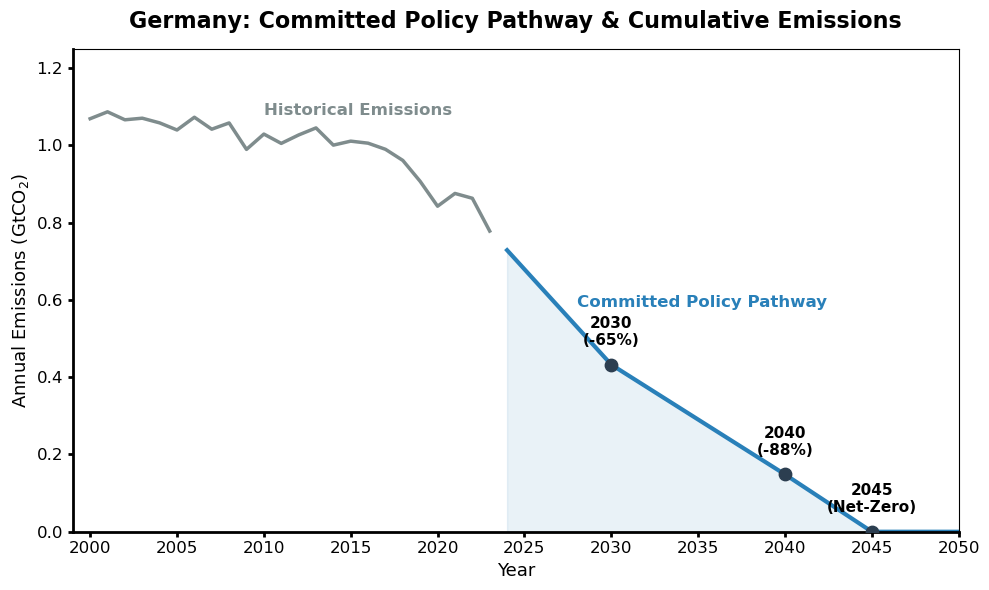

  ANALYSIS: GERMANY'S COMMITED PATHWAY VS GLOBAL FAIR SHARE (1.5°C vs 2.0°C)
  [1] Required Steepness of Policy Pathway
      ● 2024 - 2030 : -8.1% per year
      ● 2030 - 2040 : -10.2% per year
      ● 2040 - 2045 : 100% phase-out to Net-Zero
      ▶ Total Cumulative Emissions (2024-2050) : 7.12 GtCO2
--------------------------------------------------------------------------------
  [2] The Reality Check: True Overshoot & Debt Comparison
      Metric                        | 1.5°C Target       | 2.0°C Target
      ------------------------------------------------------------------
      Future Fair Share (2024-2050) |   1.83 GtCO2      |   8.68 GtCO2
      Fair Share OVERSHOOT (Future) |   5.29 GtCO2      |  -1.55 GtCO2
      Historical Debt (1970-2023)   |  33.22 GtCO2      |  33.22 GtCO2
      TRUE OVERSHOOT (Total CDR)    |  38.52 GtCO2      |  31.67 GtCO2
      ------------------------------------------------------------------
      ▶ Equivalent to (2023 basis)  |  49.5 Years      

In [59]:
# Exctracting 1990 emission
e_1990 = float(global_em_pop[(global_em_pop['country_code'] == 'DEU') & (global_em_pop['year'] == 1990)]['emission'].iloc[0])
e_1990_gt = e_1990 / 1e9  # convert unit to Gigaton from ton

# Plotting and Calculating netzero policy evaluation
analyze_german_netzero_pathway(result_1_5C, result_2_0C, total_em, e_1990_gt)

The numerical output from the committed policy pathway analysis provides an honest look at both the sheer steepness of the required emission cuts and the reality of Germany's carbon overshoot.

To start with the trajectory itself, the committed 2045 net-zero target demands incredibly aggressive reductions. Emissions must drop by an average of 8.1% every year up to 2030, and then the pace must accelerate to a 10.2% annual decline between 2030 and 2040 before hitting a complete phase-out by 2045. Even with this ambitious down-curve, Germany is projected to release a total cumulative volume of 7.12 GtCO₂ between 2024 and 2050.

Comparing this cumulative total against the 1.5°C framework brings a reality check. Since Germany's future fair share is capped at just 1.83 GtCO₂, the official policy pathway overshoots this future allocation by 5.29 GtCO₂. The situation becomes even more striking when adding the historical carbon debt of 33.22 GtCO₂ accumulated since 1970. This brings the true overshoot to a massive 38.52 GtCO₂, a carbon deficit equivalent to around 50 years of Germany's 2023 emission levels. These metrics show that a successful 1.5°C alignment is fundamentally impossible without massive, long-term carbon dioxide removal strategies.

The 2.0°C scenario offers a different but equally revealing story. Looking strictly at future emissions from 2024 onward, the committed policy pathway actually appears successful on the result, staying under the 8.68 GtCO₂ fair share budget with a surplus of 1.55 GtCO₂. However, this apparent success completely vanishes once historical accountability is factored in. Incorporating the 33.22 GtCO₂ of past debt drives the true overshoot to 31.67 GtCO₂, which is still equivalent to around 41 years of current emissions. Ultimately, the data demonstrates that even an aggressive domestic net-zero pathway cannot fully resolve the climate burden of historical emissions without active negative-emission interventions.

## 4. Tracking the Real Emission Changes in Germany

Finally, the analysis shifts focus to examine how Germany's individual sectors have been reducing their greenhouse gas emissions in the real world over the past two decades. 

To address this question, the primary Destatis dataset (`sector_em`) is utilized to analyze the top-level contributors. This exploration evaluates each sector across three key metrics: (1) the long-term historical trend, (2) the overall share of cumulative national emissions, and (3) the absolute percentage reduction achieved in 2023 relative to the 2000 baseline. 
To keep the focus on the most impactful emission sources, the analysis isolates the top largest sectors and groups the remaining activities into a single miscellaneous category using `generate_sectoral_emissions_table` function.

In [60]:
high_sector_table = generate_sectoral_emissions_table(sector_em, start_year=2000, end_year=2023, top_n=10)
display(HTML(high_sector_table))

,,Cumulative Share (%),Trend (2000-2023),Direction,Growth Rate (%)
sector_code,sector_name,,,,
WZ08-D,"Electricity, gas, steam, air conditioning supply",31.71,"<polyline points=""0.0,8.180149707613925 5.217391304347826,5.97924289380558 10.434782608695652,5.850659902662603 15.652173913043478,3.0203061645423226 20.869565217391305,3.359467880207557 26.086956521739133,3.786247646332921 31.304347826086957,2.591068448426732 36.52173913043478,1.2564897095699123 41.73913043478261,2.9359206899825345 46.95652173913044,5.666166321263244 52.173913043478265,3.807076324865875 57.391304347826086,3.8675221785730756 62.608695652173914,0.7153187593775101 67.82608695652173,0.0 73.04347826086956,2.3719931520040483 78.26086956521739,3.9600921803595774 83.47826086956522,4.579154879906206 88.69565217391305,7.650025004990109 93.91304347826087,9.614168450335555 99.1304347826087,17.090277986014282 104.34782608695653,22.338660569355127 109.56521739130434,18.342632851016443 114.78260869565217,17.239622697758797 120.0,25.0"" fill=""none"" stroke=""#555555"" stroke-width=""2"" stroke-linejoin=""round""/>",▼,-34.68
HH,Private Households,21.82,"<polyline points=""0.0,7.202640206258597 5.217391304347826,0.0 10.434782608695652,2.9375103201468526 15.652173913043478,2.860399040433414 20.869565217391305,5.821778021234891 26.086956521739133,7.883526823420173 31.304347826086957,6.441604705095077 36.52173913043478,17.132554767033835 41.73913043478261,7.725965787951019 46.95652173913044,11.661716435007087 52.173913043478265,6.543688292937048 57.391304347826086,14.570802834399226 62.608695652173914,10.38957826912453 67.82608695652173,7.6994793183490735 73.04347826086956,16.785123085025532 78.26086956521739,14.633222698124676 83.47826086956522,13.530849114367308 88.69565217391305,13.678488320291263 93.91304347826087,14.035556815265554 99.1304347826087,11.509088250381087 104.34782608695653,17.913442103073713 109.56521739130434,17.528814880566003 114.78260869565217,19.485942074043713 120.0,25.0"" fill=""none"" stroke=""#555555"" stroke-width=""2"" stroke-linejoin=""round""/>",▼,-17.96
WZ08-C,Manufacturing,21.12,"<polyline points=""0.0,0.0 5.217391304347826,5.920338396764009 10.434782608695652,8.064003163722216 15.652173913043478,6.899252760096623 20.869565217391305,5.087060230049222 26.086956521739133,7.893504700146252 31.304347826086957,7.294008949727626 36.52173913043478,1.513288580561806 41.73913043478261,1.332090056777492 46.95652173913044,15.485379760899612 52.173913043478265,7.548509377080137 57.391304347826086,8.636414835126633 62.608695652173914,10.85534316245336 67.82608695652173,10.155345273680405 73.04347826086956,11.335613248293019 78.26086956521739,6.988276332981762 83.47826086956522,5.094274208587414 88.69565217391305,2.17991816757608 93.91304347826087,8.13851371049913 99.1304347826087,11.19940159506408 104.34782608695653,14.837615496142817 109.56521739130434,9.33836851330511 114.78260869565217,17.259778812481688 120.0,25.0"" fill=""none"" stroke=""#555555"" stroke-width=""2"" stroke-linejoin=""round""/>",▼,-18.75
WZ08-A,"Agriculture, forestry and fishing",6.76,"<polyline points=""0.0,17.62528792116874 5.217391304347826,15.679776919294396 10.434782608695652,20.73670797308398 15.652173913043478,22.758874694202852 20.869565217391305,24.831594992140154 26.086956521739133,25.0 31.304347826086957,15.764917830344057 36.52173913043478,15.526868960499392 41.73913043478261,13.825161800120998 46.95652173913044,13.351346293376585 52.173913043478265,12.686147549028236 57.391304347826086,11.06369972784495 62.608695652173914,10.154979748778409 67.82608695652173,7.453721346962325 73.04347826086956,0.9427515680694434 78.26086956521739,0.0 83.47826086956522,2.663833908945062 88.69565217391305,5.760874531039654 93.91304347826087,8.796728621179383 99.1304347826087,11.572470085875718 104.34782608695653,13.085817180124938 109.56521739130434,16.40671440525947 114.78260869565217,18.858932073683135 120.0,21.235786502673747"" fill=""none"" stroke=""#555555"" stroke-width=""2"" stro

The initial filtering reveals that the utility sector, specifically `Electricity, gas, steam, and air conditioning supply`, holds the largest total share of Germany's emissions. This is followed closely by the `Private Households` sector, which includes domestic energy consumption, private transport, and other household processes. 
The third largest contributor is the `Manufacturing` sector.  The most encouraging finding here is that all three high-impact sectors show a clear, consistent downward trend over the analysis period.

The analysis will also dive into this detailed Manufacturing sub-sectoral hierarchy to identify the specific industries driving or hindering Germany's emission reductions. Because this sector comprises 19 distinct sub-sectors and serves as the backbone of Germany's industrial economy, it provides deeper insights into corporate climate progress.

In [61]:
mfg_subsector_table = generate_sectoral_emissions_table(mfg_sub_em, start_year=2000, end_year=2023, top_n=10)
display(HTML(mfg_subsector_table))

,,Cumulative Share (%),Trend (2000-2023),Direction,Growth Rate (%)
sector_code,sector_name,,,,
WZ08-24,Manufacture of basic metals,25.71,"<polyline points=""0.0,2.3788775946651626 5.217391304347826,10.299614211034392 10.434782608695652,10.347321314595806 15.652173913043478,10.322928637717924 20.869565217391305,8.958308905522642 26.086956521739133,9.492317397915818 31.304347826086957,5.036520354549172 36.52173913043478,3.080447863846892 41.73913043478261,5.076427956440526 46.95652173913044,25.0 52.173913043478265,7.913554889574005 57.391304347826086,9.295141740625649 62.608695652173914,12.600265150113584 67.82608695652173,11.383707442398478 73.04347826086956,10.361534961827992 78.26086956521739,2.5888566329377873 83.47826086956522,3.5670526515831114 88.69565217391305,0.0 93.91304347826087,1.9425964519146355 99.1304347826087,5.386679495262037 104.34782608695653,14.153678712378841 109.56521739130434,4.986677326299372 114.78260869565217,11.062155203742646 120.0,12.735784348367572"" fill=""none"" stroke=""#555555"" stroke-width=""2"" stroke-linejoin=""round""/>",▼,-14.00
WZ08-23,Manufacture of other non-metallic mineral products,17.49,"<polyline points=""0.0,0.0 5.217391304347826,7.52292104659049 10.434782608695652,10.902220868428028 15.652173913043478,7.86933753311456 20.869565217391305,4.846710320744673 26.086956521739133,11.915584258816942 31.304347826086957,8.863095111616168 36.52173913043478,4.802472111818425 41.73913043478261,6.802376429382235 46.95652173913044,14.647542784298993 52.173913043478265,13.970995768071456 57.391304347826086,10.765261736286808 62.608695652173914,13.047563717762504 67.82608695652173,14.5554110898354 73.04347826086956,13.770511979662642 78.26086956521739,15.060382020701853 83.47826086956522,14.951953354334496 88.69565217391305,12.768344042181774 93.91304347826087,13.346139247437932 99.1304347826087,14.09773954800521 104.34782608695653,11.08411911746996 109.56521739130434,12.63365257052755 114.78260869565217,16.506473581495392 120.0,25.0"" fill=""none"" stroke=""#555555"" stroke-width=""2"" stroke-linejoin=""round""/>",▼,-31.15
WZ08-20,Manufacture of chemicals and chemical products,17.12,"<polyline points=""0.0,0.46178713542756 5.217391304347826,0.0 10.434782608695652,0.15118902600072204 15.652173913043478,6.216941168104768 20.869565217391305,5.430584038389778 26.086956521739133,8.965702422012605 31.304347826086957,12.759627989737304 36.52173913043478,4.1352619357604254 41.73913043478261,2.899857317776906 46.95652173913044,6.611418732609334 52.173913043478265,11.244984270536559 57.391304347826086,10.703217754568012 62.608695652173914,10.901246052610233 67.82608695652173,12.43424567165434 73.04347826086956,14.417049840628405 78.26086956521739,14.335930561067228 83.47826086956522,13.448039416354824 88.69565217391305,11.336877597336098 93.91304347826087,16.582628161874858 99.1304347826087,18.218899018635504 104.34782608695653,16.6678599736696 109.56521739130434,15.476963079147296 114.78260869565217,22.200045043103415 120.0,25.0"" fill=""none"" stroke=""#555555"" stroke-width=""2"" stroke-linejoin=""round""/>",▼,-39.04
WZ08-19,Manufacture of coke and refined petroleum products,14.30,"<polyline points=""0.0,4.6332395001912765 5.217391304347826,8.514548549916206 10.434782608695652,8.540578036891205 15.652173913043478,14.290626623945721 20.869565217391305,8.997315347694997 26.086956521739133,0.0 31.304347826086957,6.327024588605525 36.52173913043478,9.312207936878744 41.73913043478261,5.3132281277960764 46.95652173913044,2.5322223217788142 52.173913043478265,8.779634857485753 57.391304347826086,8.909464983167652 62.608695652173914,9.326772975098024 67.82608695652173,3.0079360527907326 73.04347826086956,6.799336771322601 78.26086956521739,5.902792990101084 83.47826086956522,4.249049570501505 88.69565217391305,4.9933867770000475 93.91304347826087,14.500417989825811 99.1304347826087,17.09137562774941 104.34782608695653,20.43657211188015 109.56521739130434,19.728377719960882 114.78260869565217,13.480830455233532

Manufacturing sub-sectors reveal that the internal emission dynamics are heavily dominated by heavy industries. Specifically, the manufacture of basic metals, chemical products, and non-metallic mineral products accounts for the vast majority of cumulative industrial emissions. Mirroring the high-level sectors, these carbon-intensive chemical and metal industries also display a sharp downward trajectory in their emission profiles. 

In contrast to the broad decline across heavy industries, the data captures an unexpected upward trend in the wood and paper manufacturing sectors. This unique increase likely reflects a broader structural shift in the economy, pointing to a transition where traditional metal or plastic materials are being actively replaced by wood- and paper-based alternatives.

## 5. Conclusion and Discussion

### Summary of Findings

This computational analysis examines the global carbon debt and budget methodology, evaluates the sufficiency of future German emission pathways, and analyzes two decades of German sectoral emission data. The findings emphasize that managing greenhouse gas emissions requires treating the atmosphere as a global common rather than a resource for individual nations, necessitating a realistic assessment of current positions. The data shows that Germany holds the third-largest historical carbon debt globally. Under a business-as-usual scenario, Germany's allocated carbon budget for a 1.5°C target was already depleted in 2025, while the budget for a 2.0°C target is estimated to have approximately 11 years remaining. 

Furthermore, even if Germany avoids current emissions and achieves its committed 2045 carbon neutrality target, cumulative emissions will still overshoot the 1.5°C budget when factoring in historical debt. For the 2.0°C target, the future policy pathway stays within the allocated budget. However, when evaluating the adjusted carbon budget that includes historical emissions, a substantial debt of about 30 GtCO₂ remains. Resolving this deficit requires moving beyond domestic net-zero targets to integrate international cooperation and active atmospheric carbon removal strategies. 

Looking at real sectoral trends from 2000 to 2023, major emission sources including private households, electricity supply, and manufacturing show steady declines. Within manufacturing, dominant sectors like basic metals, chemicals, and mineral products display a downward trend. Concurrently, emissions from paper and wood industries are rising, which signals a clear industrial transition.

### Discussion of Implications

The concepts of historical responsibility and carbon debt depend heavily on the selected baseline year. Choosing an earlier starting year increases the calculated debt for early-industrialized nations like the United States while expanding the remaining budget for later-industrialized nations like China, making this a sensitive topic in international climate politics. Although some frameworks utilize a 1750 baseline from the start of the Industrial Revolution, data limitations prevented its application in this analysis.

Additionally, comprehensive greenhouse gas accounting involves factors beyond gross emissions, including forest carbon sinks, carbon removal technologies, and international carbon credits. Consequently, this analysis serves as a macro-scale framework to understand the structural realities of emissions and budgets in Germany.

## 6. References

### Primary Data Sources
1. **Federal Statistical Office of Germany (Destatis).** "Greenhouse gas emissions: Germany, years, economic activities (2000-2023)". GENESIS-Online Database. Available at: https://www-genesis.destatis.de/datenbank/online/url/4e49a5ed

2. **European Commission, Joint Research Centre (JRC).** "GHG emissions of all world countries (2025)". EDGAR - Emissions Database for Global Atmospheric Research. Available at: https://edgar.jrc.ec.europa.eu/report_2025#data_download

3. **United Nations Department of Economic and Social Affairs (UN DESA).** "World Population Prospects: Standard Projections". Population Division. Available at: https://population.un.org/wpp/downloads?folder=Standard%20Projections&group=Most%20used

### Methodology and Policy Guidelines
4. **IPCC.** "Estimates of historical carbon dioxide (CO2) emissions and remaining carbon budgets". at: https://www.ipcc.ch/report/ar6/wg1/chapter/summary-for-policymakers/#:~:text=Table%20SPM.2%20%7C%20Estimates%20of%20historical%20carbon%20dioxide%20(CO2)%20emissions%20and%20remaining%20carbon%20budgets.


5. **Nature Communications.** "Estimating countries’ additional carbon accountability for closing the mitigation gap based on past and future emissions". *Nature*, 2024. Available at: https://doi.org/10.1038/s41467-024-54039-x

6. **Helmholtz Climate Initiative.** "NET-ZERO-2050 CLUSTER: Defining the German Carbon Budget". GEOMAR Helmholtz Centre for Ocean Research Kiel. Available at: https://oceanrep.geomar.de/id/eprint/57744/

7. **Climate Action Tracker (CAT).** "Germany's proposed 2030 national target not yet 1.5°C compatible". Climate Analytics and NewClimate Institute. Available at: https://climateactiontracker.org/publications/germanys-proposed-2030-national-target-not-yet-15c-compatible/